# 📈 Regression Models (Unit 3)
Build and evaluate linear, polynomial, and regularized regression models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=';')
df_clean = df.drop_duplicates().reset_index(drop=True)

X = df_clean.drop('quality', axis=1)
y = df_clean['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print(f"Data ready: train={X_train_scaled.shape}, test={X_test_scaled.shape}")

Data ready: train=(1087, 11), test=(272, 11)


## Cell 12: Helper Function - Evaluation Metrics (Unit 3)
Regression metrics: **MAE, MSE, RMSE, R²**

In [2]:
# Unit 3: Regression evaluation metrics - MAE, MSE, RMSE, R-squared

def evaluate_regression(model, X_test, y_test, model_name):
    """Evaluate regression model and return metrics dictionary"""
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results = {
        'Model': model_name,
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'R2_Score': round(r2, 4)
    }

    print(f"\n{model_name} RESULTS")
    print("-" * 50)
    print(f"MAE  (Mean Absolute Error):          {mae:.4f}")
    print(f"MSE  (Mean Squared Error):           {mse:.4f}")
    print(f"RMSE (Root Mean Squared Error):      {rmse:.4f}")
    print(f"R²   (Coefficient of Determination): {r2:.4f}")
    print(f"→ Model explains {r2*100:.2f}% of variance in wine quality")

    return results

# List to store all results for final comparison
all_results = []
model_objects = {}

## Cell 13: Simple Linear Regression (Unit 3)
Baseline model using only `alcohol` — the feature with the highest correlation to quality.

Coefficient (slope): 0.3891
Intercept: 5.6366
Interpretation: 1 unit increase in (scaled) alcohol → 0.3891 change in quality score

Simple Linear Regression RESULTS
--------------------------------------------------
MAE  (Mean Absolute Error):          0.5675
MSE  (Mean Squared Error):           0.5368
RMSE (Root Mean Squared Error):      0.7327
R²   (Coefficient of Determination): 0.2421
→ Model explains 24.21% of variance in wine quality


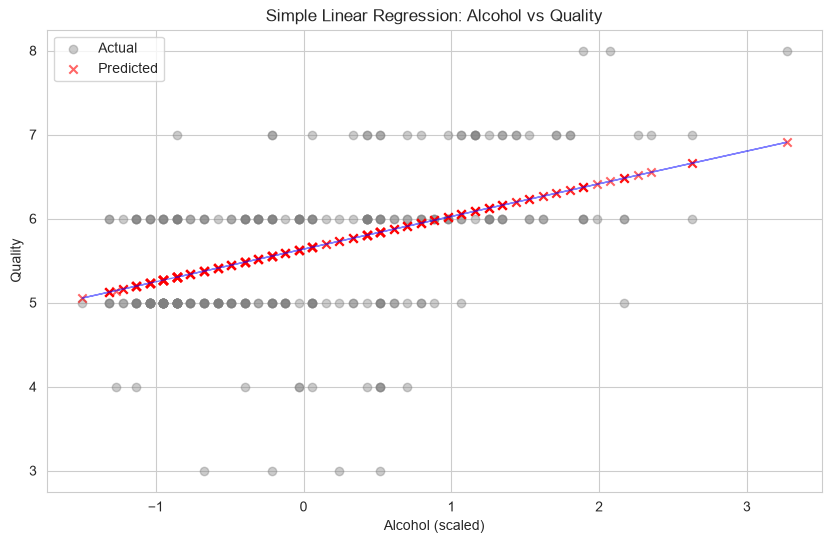

In [3]:
# Unit 3: Simple Linear Regression (one feature - 'alcohol', highest correlation)

# Reshape for single feature
X_train_slr = X_train_scaled[['alcohol']]
X_test_slr = X_test_scaled[['alcohol']]

slr_model = LinearRegression()
slr_model.fit(X_train_slr, y_train)
model_objects['Simple LR'] = (slr_model, X_test_slr)

print(f"Coefficient (slope): {slr_model.coef_[0]:.4f}")
print(f"Intercept: {slr_model.intercept_:.4f}")
print(f"Interpretation: 1 unit increase in (scaled) alcohol → "
      f"{slr_model.coef_[0]:.4f} change in quality score")

result = evaluate_regression(slr_model, X_test_slr, y_test, 
                             "Simple Linear Regression")
all_results.append(result)

# Visualization
plt.figure(figsize=(10, 6))
plt.scatter(X_test_slr, y_test, alpha=0.4, label='Actual', color='gray')
plt.scatter(X_test_slr, slr_model.predict(X_test_slr), alpha=0.6, 
            label='Predicted', color='red', marker='x')
plt.plot(X_test_slr, slr_model.predict(X_test_slr), color='blue', linewidth=1, alpha=0.5)
plt.xlabel('Alcohol (scaled)')
plt.ylabel('Quality')
plt.title('Simple Linear Regression: Alcohol vs Quality')
plt.legend()
plt.show()

## Cell 14: Multiple Linear Regression (Unit 3)

In [4]:
# Unit 3: Multiple Linear Regression (all features)

mlr_model = LinearRegression()
mlr_model.fit(X_train_scaled, y_train)
model_objects['Multiple LR'] = (mlr_model, X_test_scaled)

# Show coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': mlr_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Feature Coefficients:")
print(coefficients.to_string(index=False))

result = evaluate_regression(mlr_model, X_test_scaled, y_test, 
                             "Multiple Linear Regression")
all_results.append(result)

Feature Coefficients:
             Feature  Coefficient
             alcohol     0.333970
    volatile acidity    -0.178494
           sulphates     0.148499
total sulfur dioxide    -0.123600
                  pH    -0.121548
           chlorides    -0.115971
       fixed acidity    -0.049675
 free sulfur dioxide     0.048723
             density     0.042064
         citric acid    -0.019148
      residual sugar    -0.005231

Multiple Linear Regression RESULTS
--------------------------------------------------
MAE  (Mean Absolute Error):          0.5041
MSE  (Mean Squared Error):           0.4310
RMSE (Root Mean Squared Error):      0.6565
R²   (Coefficient of Determination): 0.3915
→ Model explains 39.15% of variance in wine quality


## Cell 15: Polynomial Regression (Unit 3)
Degree=2 captures non-linear relationships (e.g., optimal alcohol level). Higher degrees would overfit.

Original features: 11
Polynomial features (degree=2): 77

Polynomial Regression (degree=2) RESULTS
--------------------------------------------------
MAE  (Mean Absolute Error):          0.4937
MSE  (Mean Squared Error):           0.4346
RMSE (Root Mean Squared Error):      0.6593
R²   (Coefficient of Determination): 0.3864
→ Model explains 38.64% of variance in wine quality


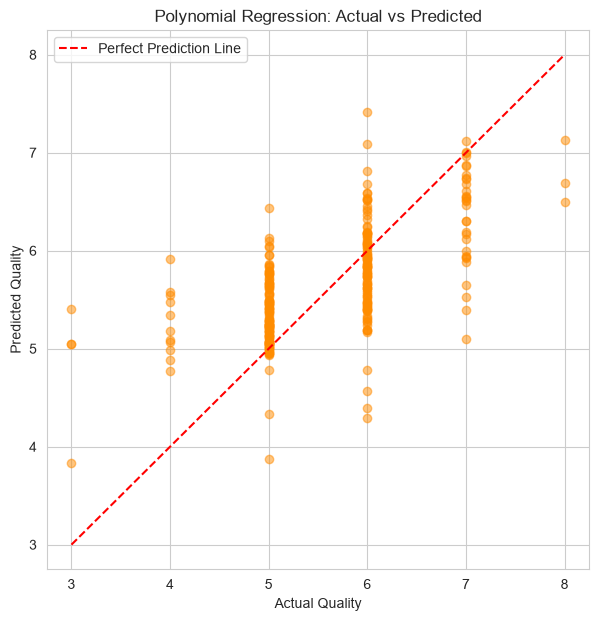

In [5]:
# Unit 3: Polynomial Regression (degree=2 - captures non-linear relationships)

# Create polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print(f"Original features: {X_train_scaled.shape[1]}")
print(f"Polynomial features (degree=2): {X_train_poly.shape[1]}")

# Train on polynomial features
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
model_objects['Polynomial'] = (poly_model, X_test_poly)

result = evaluate_regression(poly_model, X_test_poly, y_test, 
                             "Polynomial Regression (degree=2)")
all_results.append(result)

# Plot: Actual vs Predicted
plt.figure(figsize=(7, 7))
plt.scatter(y_test, poly_model.predict(X_test_poly), alpha=0.5, color='darkorange')
plt.plot([3, 8], [3, 8], 'r--', label='Perfect Prediction Line')
plt.xlabel('Actual Quality')
plt.ylabel('Predicted Quality')
plt.title('Polynomial Regression: Actual vs Predicted')
plt.legend()
plt.show()

## Cell 16: Ridge Regression (Unit 3 - L2 Regularization)
Ridge shrinks coefficients toward zero to reduce overfitting.

In [6]:
# Unit 3: Ridge Regression (L2 regularization - reduces overfitting)

ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
model_objects['Ridge'] = (ridge_model, X_test_scaled)

result = evaluate_regression(ridge_model, X_test_scaled, y_test, 
                             "Ridge Regression (alpha=1.0)")
all_results.append(result)

# Compare coefficients: Multiple LR vs Ridge
coef_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Multiple_LR': mlr_model.coef_,
    'Ridge': ridge_model.coef_
})
print("\nCoefficient Shrinkage (Ridge reduces large coefficients):")
print(coef_comparison.round(4).to_string(index=False))


Ridge Regression (alpha=1.0) RESULTS
--------------------------------------------------
MAE  (Mean Absolute Error):          0.5041
MSE  (Mean Squared Error):           0.4308
RMSE (Root Mean Squared Error):      0.6564
R²   (Coefficient of Determination): 0.3918
→ Model explains 39.18% of variance in wine quality

Coefficient Shrinkage (Ridge reduces large coefficients):
             Feature  Multiple_LR   Ridge
       fixed acidity      -0.0497 -0.0478
    volatile acidity      -0.1785 -0.1783
         citric acid      -0.0191 -0.0190
      residual sugar      -0.0052 -0.0047
           chlorides      -0.1160 -0.1157
 free sulfur dioxide       0.0487  0.0485
total sulfur dioxide      -0.1236 -0.1233
             density       0.0421  0.0402
                  pH      -0.1215 -0.1203
           sulphates       0.1485  0.1485
             alcohol       0.3340  0.3327


## Cell 17: Lasso Regression (Unit 3 - L1 Regularization)
Lasso can shrink unimportant feature coefficients exactly to zero (automatic feature selection).

In [7]:
# Unit 3: Lasso Regression (L1 regularization - can shrink features to zero)

lasso_model = Lasso(alpha=0.01, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
model_objects['Lasso'] = (lasso_model, X_test_scaled)

result = evaluate_regression(lasso_model, X_test_scaled, y_test, 
                             "Lasso Regression (alpha=0.01)")
all_results.append(result)

# Show which features Lasso eliminated (coefficient = 0)
lasso_coef = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso_model.coef_
})
eliminated = lasso_coef[lasso_coef['Coefficient'] == 0]['Feature'].tolist()
print(f"\nFeatures eliminated by Lasso (coefficient = 0): {eliminated}")


Lasso Regression (alpha=0.01) RESULTS
--------------------------------------------------
MAE  (Mean Absolute Error):          0.5012
MSE  (Mean Squared Error):           0.4254
RMSE (Root Mean Squared Error):      0.6522
R²   (Coefficient of Determination): 0.3995
→ Model explains 39.95% of variance in wine quality

Features eliminated by Lasso (coefficient = 0): ['fixed acidity', 'citric acid', 'residual sugar', 'density']


## Cell 18: Elastic Net (Unit 3 - Combined L1 + L2)

In [8]:
# Unit 3: Elastic Net (combines L1 and L2 regularization)

en_model = ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=42)
en_model.fit(X_train_scaled, y_train)
model_objects['ElasticNet'] = (en_model, X_test_scaled)

result = evaluate_regression(en_model, X_test_scaled, y_test, 
                             "Elastic Net (alpha=0.01, l1_ratio=0.5)")
all_results.append(result)


Elastic Net (alpha=0.01, l1_ratio=0.5) RESULTS
--------------------------------------------------
MAE  (Mean Absolute Error):          0.5018
MSE  (Mean Squared Error):           0.4259
RMSE (Root Mean Squared Error):      0.6526
R²   (Coefficient of Determination): 0.3987
→ Model explains 39.87% of variance in wine quality
